# Model

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

from src import config as c, data, model

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (10, 3), "axes.grid": True, "grid.alpha": .3})

## Dataset

In [2]:
products = ["gasoline", "distillate", "bunker"]
datasets = {p: data.dataset(p) for p in products}

In [3]:
{p: df.shape for p, df in datasets.items()}

{'gasoline': (321, 6), 'distillate': (321, 8), 'bunker': (321, 7)}

In [4]:
# the walk-through uses distillate; the backtest below runs all three
df, lag = datasets["distillate"], c.DEMAND_LAG["distillate"]
df.tail(3)

,demand,hdd,hdd_oil,ind,ind_manuf,truck,real_price,product_supplied_4wk
month,,,,,,,,
2026-07-01,"3,685.00",24.00,33.00,102.84,99.24,116.30,1.51,"3,676.25"
2026-08-01,NaN,4.00,7.00,103.05,99.40,112.80,1.49,"3,797.75"
2026-09-01,NaN,5.00,8.00,103.07,99.10,114.40,1.63,"3,636.00"


## Forecast setup

In [5]:
origin = pd.Timestamp("2023-12-01")  # a past origin: what was published by 31 December 2023
origin

Timestamp('2023-12-01 00:00:00')

In [6]:
model.HORIZON

12

In [7]:
lag  # demand is published two months late

2

In [8]:
list(range(lag, lag + 12))  # the demand prints the model sees: t-2 ... t-13

[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]

In [9]:
months = pd.date_range(origin + pd.DateOffset(months=1), periods=model.HORIZON, freq="MS")
months  # target months t+1 ... t+12

DatetimeIndex(['2024-01-01', '2024-02-01', '2024-03-01', '2024-04-01',
               '2024-05-01', '2024-06-01', '2024-07-01', '2024-08-01',
               '2024-09-01', '2024-10-01', '2024-11-01', '2024-12-01'],
              dtype='datetime64[us]', freq='MS')

In [10]:
# the naive's reference: same calendar month, latest year published at the origin
pd.Series([m - pd.DateOffset(months=model.back(s, lag)) for s, m in enumerate(months, 1)],
          index=months)

2024-01-01   2023-01-01
2024-02-01   2023-02-01
2024-03-01   2023-03-01
2024-04-01   2023-04-01
2024-05-01   2023-05-01
2024-06-01   2023-06-01
2024-07-01   2023-07-01
2024-08-01   2023-08-01
2024-09-01   2023-09-01
2024-10-01   2023-10-01
2024-11-01   2022-11-01
2024-12-01   2022-12-01
Freq: MS, dtype: datetime64[us]

In [11]:
c.EXCLUDE_YEARS

[2020]

## Features

In [12]:
X, y = model.features(df, lag, step=12)

In [13]:
X.columns

Index(['yoy_lag2', 'yoy_lag3', 'yoy_lag4', 'yoy_lag5', 'yoy_lag6', 'yoy_lag7',
       'yoy_lag8', 'yoy_lag9', 'yoy_lag10', 'yoy_lag11', 'yoy_lag12',
       'yoy_lag13', 'hdd', 'hdd_oil', 'ind', 'ind_manuf', 'truck',
       'real_price', 'product_supplied_4wk'],
      dtype='str')

In [14]:
X.loc[[origin]].T  # the information set at the origin, in year-on-year terms

month,2023-12-01
yoy_lag2,-0.02
yoy_lag3,-0.06
yoy_lag4,0.03
yoy_lag5,-0.04
yoy_lag6,-0.02
yoy_lag7,0.01
yoy_lag8,-0.02
yoy_lag9,-0.02
yoy_lag10,-0.09
yoy_lag11,-0.04


In [15]:
# the target: log of December 2024 over December 2022, the naive's reference
target = origin + pd.DateOffset(months=12)
reference = target - pd.DateOffset(months=model.back(12, lag))
target, reference, y.loc[origin], np.log(df.loc[target, "demand"] / df.loc[reference, "demand"])

(Timestamp('2024-12-01 00:00:00'),
 Timestamp('2022-12-01 00:00:00'),
 np.float64(-0.013269833784470109),
 np.float64(-0.01326983378446999))

In [16]:
# what each driver at the origin describes, and when it was published
month_end = origin + pd.offsets.MonthEnd(0)
info = {}
for name, s in data.predictors("distillate").items():
    if name == "product_supplied_4wk":
        delay = pd.Timedelta(days=c.WEEKLY_LAG_DAYS)
    else:
        delay = pd.offsets.MonthEnd(c.LAG[name])
    known = s.dropna()[s.dropna().index + delay <= month_end]
    info[name] = {"period_end": known.index[-1], "available_at": known.index[-1] + delay}
pd.DataFrame(info).T

,period_end,available_at
hdd,2023-11-30,2023-12-31
hdd_oil,2023-11-30,2023-12-31
ind,2023-11-30,2023-12-31
ind_manuf,2023-11-30,2023-12-31
truck,2023-09-30,2023-12-31
real_price,2023-11-30,2023-12-31
product_supplied_4wk,2023-12-22,2023-12-28


In [17]:
rows = model.trainable(y, step=12, lag=lag, origin=origin)
rows.sum()

np.int64(118)

In [18]:
# last training origin, its target, and when that target was published: by the origin
last = X.index[rows].max()
last, last + pd.DateOffset(months=12), last + pd.DateOffset(months=12 + lag)

(Timestamp('2022-10-01 00:00:00'),
 Timestamp('2023-10-01 00:00:00'),
 Timestamp('2023-12-01 00:00:00'))

In [19]:
X.index[rows].year.value_counts().sort_index()

month
2010    12
2011    12
2012    12
2013    12
2014    12
2015    12
2016    12
2017    12
2018    12
2022    10
Name: count, dtype: int64

In [20]:
# scaling changes nothing for a tree: same rows, raw against standardised
scaled = (X - X[rows].mean()) / X[rows].std()
raw_fit = XGBRegressor(**model.PARAMS).fit(X[rows], y[rows]).predict(X.loc[[origin]])
scaled_fit = XGBRegressor(**model.PARAMS).fit(scaled[rows], y[rows]).predict(scaled.loc[[origin]])
raw_fit, scaled_fit

(array([0.02169378], dtype=float32), array([0.02169378], dtype=float32))

## Validation

In [21]:
# expanding window: each block is scored by a model fitted on targets published before it
fit_X, fit_y = X[rows], y[rows]
edges = [len(fit_X) * k // 4 for k in range(5)]
for k, (a, b) in enumerate(zip(edges[1:-1], edges[2:]), 1):
    train = fit_X.index[fit_X.index + pd.DateOffset(months=12 + lag) <= fit_X.index[a]]
    print(f"fold {k}   train {train[0]:%Y-%m} to {train[-1]:%Y-%m}"
          f"   validate {fit_X.index[a]:%Y-%m} to {fit_X.index[b - 1]:%Y-%m}")

fold 1   train 2010-01 to 2011-04   validate 2012-06 to 2014-11
fold 2   train 2010-01 to 2013-10   validate 2014-12 to 2017-04
fold 3   train 2010-01 to 2016-03   validate 2017-05 to 2022-10


In [22]:
# RMSE of the log deviation, read as a % error
example = {"learning_rate": 0.03, "max_depth": 3, "n_estimators": 600}
100 * np.sqrt(model.cv_score(fit_X, fit_y, step=12, lag=lag, params=example))

np.float64(5.7818595475482315)

## Hyperparameters

In [23]:
model.GRID

[{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200},
 {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 600},
 {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 200},
 {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 600},
 {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200},
 {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 600},
 {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200},
 {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 600}]

In [24]:
cv = pd.DataFrame(model.GRID)
cv["rmse %"] = [100 * np.sqrt(model.cv_score(fit_X, fit_y, 12, lag, p)) for p in model.GRID]
cv.sort_values("rmse %")

,learning_rate,max_depth,n_estimators,rmse %
2,0.03,5,200,5.71
3,0.03,5,600,5.72
0,0.03,3,200,5.76
1,0.03,3,600,5.78
4,0.10,3,200,5.93
5,0.10,3,600,5.93
7,0.10,5,600,5.93
6,0.10,5,200,5.94


In [25]:
params = model.tune(df, lag, origin)
params

{'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 200}

## Forecast

In [26]:
# one model per horizon: each step has its own target and its own training rows
pd.Series({step: model.trainable(model.features(df, lag, step)[1], step, lag, origin).sum()
           for step in range(1, model.HORIZON + 1)})

1     141
2     140
3     139
4     138
5     137
6     136
7     135
8     134
9     133
10    132
11    120
12    118
dtype: int64

In [27]:
# step 1 by hand: fit, predict the deviation from the naive, apply it
X1, y1 = model.features(df, lag, step=1)
rows1 = model.trainable(y1, 1, lag, origin)
fit = XGBRegressor(**model.PARAMS, **params).fit(X1[rows1], y1[rows1])
deviation = fit.predict(X1.loc[[origin]])[0]
deviation, model.seasonal_naive(df, lag, origin).iloc[0] * np.exp(deviation)

(np.float32(0.0052695465), np.float64(3987.9595450162888))

In [28]:
path = model.forecast(df, lag, origin, params)
path.round(0)

2024-01-01   3,988.00
2024-02-01   4,026.00
2024-03-01   4,160.00
2024-04-01   3,959.00
2024-05-01   4,009.00
2024-06-01   4,025.00
2024-07-01   3,681.00
2024-08-01   4,154.00
2024-09-01   3,970.00
2024-10-01   4,231.00
2024-11-01   4,143.00
2024-12-01   3,919.00
Freq: MS, dtype: float64

## Baseline

In [29]:
naive = model.seasonal_naive(df, lag, origin)
pd.DataFrame({"actual": df["demand"].reindex(path.index), "xgboost": path, "naive": naive}).round(0)

,actual,xgboost,naive
2024-01-01,"3,856.00","3,988.00","3,967.00"
2024-02-01,"3,900.00","4,026.00","3,999.00"
2024-03-01,"3,693.00","4,160.00","4,113.00"
2024-04-01,"3,793.00","3,959.00","3,879.00"
2024-05-01,"3,769.00","4,009.00","3,919.00"
2024-06-01,"3,663.00","4,025.00","3,978.00"
2024-07-01,"3,699.00","3,681.00","3,583.00"
2024-08-01,"3,889.00","4,154.00","4,052.00"
2024-09-01,"3,687.00","3,970.00","3,858.00"
2024-10-01,"4,131.00","4,231.00","4,061.00"


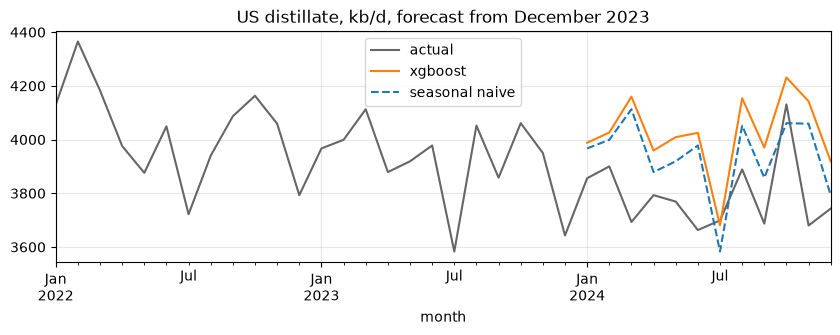

In [30]:
ax = df["demand"].loc["2022":"2024"].plot(color="0.4", label="actual")
path.plot(ax=ax, color="C1", label="xgboost")
naive.plot(ax=ax, color="C0", ls="--", label="seasonal naive")
ax.set_title("US distillate, kb/d, forecast from December 2023"); ax.legend();

## Evaluation

In [31]:
%%time
backtests = {p: model.backtest(datasets[p], c.DEMAND_LAG[p]) for p in products}

CPU times: user 15min 47s, sys: 1min 36s, total: 17min 24s
Wall time: 4min 50s


In [32]:
pd.DataFrame({p: params for p, (bt, params) in backtests.items()}).T  # tuned at the first origin

,learning_rate,max_depth,n_estimators
gasoline,0.03,5.00,600.00
distillate,0.10,5.00,600.00
bunker,0.03,3.00,200.00


In [33]:
bt = backtests["distillate"][0]
bt.head(12)  # one origin, twelve targets

,origin,step,reference,actual,xgboost,naive
month,,,,,,
2015-02-01,2015-01-01,1,2014-02-01,"4,559.00","4,199.95","4,160.00"
2015-03-01,2015-01-01,2,2014-03-01,"4,078.00","4,085.23","4,066.00"
2015-04-01,2015-01-01,3,2014-04-01,"4,027.00","4,091.96","3,990.00"
2015-05-01,2015-01-01,4,2014-05-01,"3,778.00","3,969.14","3,952.00"
2015-06-01,2015-01-01,5,2014-06-01,"3,897.00","3,794.14","3,902.00"
2015-07-01,2015-01-01,6,2014-07-01,"3,901.00","3,704.03","3,866.00"
2015-08-01,2015-01-01,7,2014-08-01,"3,915.00","3,785.23","3,875.00"
2015-09-01,2015-01-01,8,2014-09-01,"4,063.00","3,707.52","3,933.00"
2015-10-01,2015-01-01,9,2014-10-01,"4,014.00","4,154.28","4,266.00"


In [34]:
bt["origin"].nunique(), bt["origin"].min(), bt["origin"].max()

(127, Timestamp('2015-01-01 00:00:00'), Timestamp('2026-07-01 00:00:00'))

In [35]:
scores = pd.concat({p: model.score(bt) for p, (bt, _) in backtests.items()}, axis=1)
scores.round(2)  # MAPE % by horizon

gasoline       distillate        bunker      
      xgboost naive    xgboost naive xgboost naive
step                                              
1        1.65  1.79       3.39  3.66    5.57  6.60
2        1.83  1.78       3.66  3.62    5.75  6.64
3        1.80  1.76       3.85  3.64    6.49  6.61
4        1.75  1.76       3.96  3.67    6.79  6.63
5        1.75  1.75       3.70  3.66    7.14  6.68
6        1.84  1.73       3.88  3.69    6.97  6.70
7        1.78  1.72       4.00  3.72    6.99  6.74
8        1.68  1.72       4.04  3.74    7.08  6.67
9        1.91  1.69       4.14  3.75    7.52  6.67
10       1.84  1.70       4.04  3.73    7.89  6.72
11       2.09  2.21       4.18  4.64    8.17  6.69
12       2.05  2.19       4.31  4.72    8.29  8.96

In [36]:
summary = pd.DataFrame({p: model.score(bt).mean() for p, (bt, _) in backtests.items()}).T
summary["gain %"] = 100 * (1 - summary["xgboost"] / summary["naive"])
summary.round(2)  # MAPE % averaged over the twelve horizons

,xgboost,naive,gain %
gasoline,1.83,1.82,-0.76
distillate,3.93,3.85,-1.96
bunker,7.05,6.86,-2.84


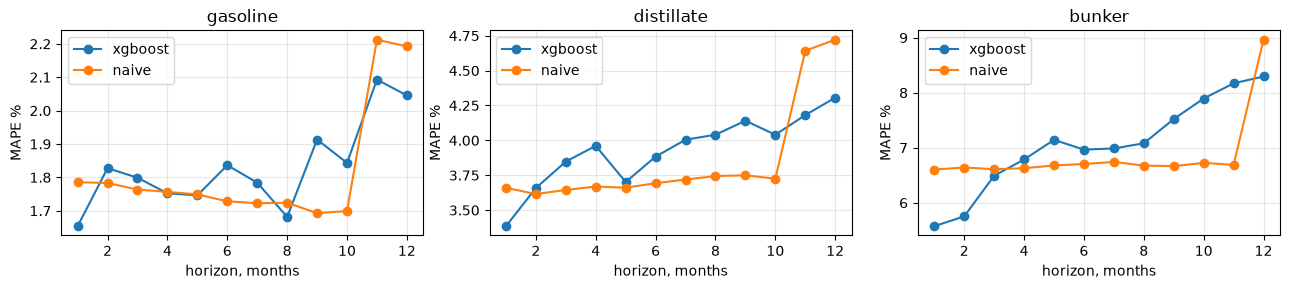

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, p in zip(axes, products):
    scores[p].plot(ax=ax, marker="o", title=p)
    ax.set_xlabel("horizon, months"); ax.set_ylabel("MAPE %")
plt.tight_layout();

## Drivers

In [38]:
# one origin a quarter, every calendar season: the full backtest at a quarter of the cost
quarterly = pd.date_range(c.BACKTEST_START, "2026-06-01", freq="3MS")  # 2020 drops out
len(quarterly)

46

In [39]:
%%time
# lags only, then one driver dropped at a time: same hyperparameters, quarterly origins
ablation = {}
for p, (_, p_params) in backtests.items():
    p_df, p_lag = datasets[p], c.DEMAND_LAG[p]
    variants = {"all drivers": p_df, "lags only": p_df[["demand"]]}
    variants |= {f"without {x}": p_df.drop(columns=x) for x in p_df.columns.drop("demand")}
    for name, frame in variants.items():
        mape = model.score(model.backtest(frame, p_lag, p_params, quarterly)[0]).mean()
        ablation[(p, name)] = mape["xgboost"]
    ablation[(p, "seasonal naive")] = mape["naive"]
ablation = pd.Series(ablation).unstack(0)
ablation.round(2)

CPU times: user 40min 49s, sys: 3min 36s, total: 44min 25s
Wall time: 11min 45s


,bunker,distillate,gasoline
all drivers,7.12,3.96,1.84
lags only,6.59,3.91,1.90
seasonal naive,6.82,3.86,1.83
without brent,7.00,NaN,NaN
without bunker_calls,7.10,NaN,NaN
without bunker_calls_gt,7.12,NaN,NaN
without cargo,7.05,NaN,NaN
without hdd,NaN,3.90,NaN
without hdd_oil,NaN,3.88,NaN
without inc,NaN,NaN,1.84


In [40]:
# change in MAPE when the driver is removed: negative means the model is better without it
(ablation - ablation.loc["all drivers"]).round(2)

,bunker,distillate,gasoline
all drivers,0.00,0.00,0.00
lags only,-0.54,-0.06,0.05
seasonal naive,-0.30,-0.11,-0.01
without brent,-0.12,NaN,NaN
without bunker_calls,-0.02,NaN,NaN
without bunker_calls_gt,-0.01,NaN,NaN
without cargo,-0.07,NaN,NaN
without hdd,NaN,-0.07,NaN
without hdd_oil,NaN,-0.09,NaN
without inc,NaN,NaN,0.00


In [41]:
%%time
# how much the score moves for no reason: same features, other seeds
seeds = {}
for seed in (1, 2, 3):
    model.PARAMS["random_state"] = seed
    for p, (_, p_params) in backtests.items():
        bt_seed = model.backtest(datasets[p], c.DEMAND_LAG[p], p_params, quarterly)[0]
        seeds[(p, seed)] = model.score(bt_seed).mean()["xgboost"]
model.PARAMS["random_state"] = 42
pd.Series(seeds).unstack(0).round(2)

CPU times: user 16min 48s, sys: 1min 2s, total: 17min 51s
Wall time: 4min 32s


,bunker,distillate,gasoline
1,7.11,3.95,1.85
2,7.14,3.82,1.87
3,7.10,3.85,1.86
